# 03 — Results analysis

Pulls every run from MLflow and builds the comparison tables and charts of the report.
Set the MLflow environment variables (or a `.env` file) before running.

In [ ]:
# Setup: only does something on Google Colab. Locally (Jupyter / VS Code with the .venv
# kernel) the project is already installed and the data is in data/, so this cell is a no-op.
import os
import sys

if "google.colab" in sys.modules:
    from google.colab import userdata

    GITHUB_USER, REPO = "Yassminefeki", "brain-tumor-mlops"
    token = userdata.get("GITHUB_TOKEN")  # Colab secret, needed while the repo is private
    if not os.path.exists(f"/content/{REPO}"):
        !git clone -q https://{token}@github.com/{GITHUB_USER}/{REPO}.git /content/{REPO}
    %cd /content/{REPO}
    !git pull -q
    !pip install -q -e .
    sys.path.insert(0, f"/content/{REPO}/src")  # make the fresh install importable now
    # MLflow runs saved to Google Drive by section 8 of 02_colab_runner.ipynb
    # (not needed if the runs were logged to DagsHub: set the MLFLOW_* variables instead).
    from google.colab import drive

    drive.mount("/content/drive")
    !cp /content/drive/MyDrive/brain-tumor-mlops-results/mlflow.db .

In [ ]:
import mlflow
import pandas as pd
import matplotlib.pyplot as plt

from brain_tumor.config import load_params, project_path
from brain_tumor.tracking import setup_mlflow

cfg = load_params()
setup_mlflow(cfg, "custom_cnn")  # connects; the experiment name does not matter here
prefix = cfg["mlflow"]["experiment_prefix"]
OUT = project_path(cfg, "reports_dir")
(OUT / "figures").mkdir(parents=True, exist_ok=True)

runs = mlflow.search_runs(search_all_experiments=True,
                          filter_string="attributes.status = 'FINISHED'")
runs = runs[runs["tags.mlflow.runName"].notna()]
print(len(runs), "finished runs")

22:59:43 | INFO    | brain_tumor.tracking | MLflow tracking: sqlite:////home/yassmine/Documents/S1/Deep_Learning/projet/brain-tumor-mlops/mlflow.db | experiment: brain-tumor/custom_cnn


17 finished runs


## 1. Main comparison table (test set, patient-level split)

In [ ]:
CLASSES = cfg["data"]["class_names"]
cols = {
    "tags.mlflow.runName": "run",
    "tags.model": "model",
    "tags.split_column": "split",
    "metrics.best_val_macro_f1": "val macro-F1",
    "metrics.test_accuracy": "test accuracy",
    "metrics.test_macro_f1": "test macro-F1",
    **{f"metrics.test_recall_{c}": f"recall {c}" for c in CLASSES},
    "metrics.test_n_parameters": "parameters",
    "metrics.test_inference_ms_per_image": "ms / image",
    "metrics.train_minutes": "train min",
}
table = runs[[c for c in cols if c in runs.columns]].rename(columns=cols)
table = table[table["model"].notna()].sort_values("test macro-F1", ascending=False)
main = table[table["split"] == "split"].round(3)
display(main)
main.to_csv(OUT / "comparison.csv", index=False)
# Markdown copy for the README / report: parameters in millions, no raw floats.
md = main.assign(parameters=(main["parameters"] / 1e6).map("{:.2f} M".format))
(OUT / "comparison.md").write_text(md.to_markdown(index=False, floatfmt=".3f") + "\n")

,run,model,split,val macro-F1,test accuracy,test macro-F1,recall meningioma,recall glioma,recall pituitary,parameters,ms / image,train min
1,resnet18-aug-fold4,resnet18,split,0.873,0.940,0.937,0.938,0.952,0.925,11178051.0,2.357,2.589
4,resnet18-aug-fold1,resnet18,split,0.978,0.933,0.929,0.955,0.941,0.900,11178051.0,2.626,2.504
5,resnet18-aug-fold0,resnet18,split,0.914,0.931,0.925,0.929,0.957,0.892,11178051.0,2.420,2.556
2,resnet18-aug-fold3,resnet18,split,0.938,0.926,0.920,0.902,0.941,0.925,11178051.0,3.189,2.188
13,resnet18-aug,resnet18,split,0.957,0.921,0.916,0.929,0.947,0.875,11178051.0,2.479,2.293
12,efficientnet_b0-aug,efficientnet_b0,split,0.946,0.917,0.909,0.920,0.936,0.883,4011391.0,8.695,3.215
3,resnet18-aug-fold2,resnet18,split,0.958,0.900,0.891,0.902,0.957,0.808,11178051.0,4.443,2.143
0,resnet18-final,resnet18,split,0.950,0.895,0.888,0.946,0.952,0.758,11178051.0,2.674,1.560
6,custom_cnn-tuned,custom_cnn,split,0.822,0.886,0.883,0.991,0.862,0.825,1239203.0,1.528,1.846
14,custom_cnn-aug,custom_cnn,split,0.933,0.871,0.862,0.777,0.936,0.858,2386595.0,1.867,3.340


2730

## 2. Accuracy vs. cost

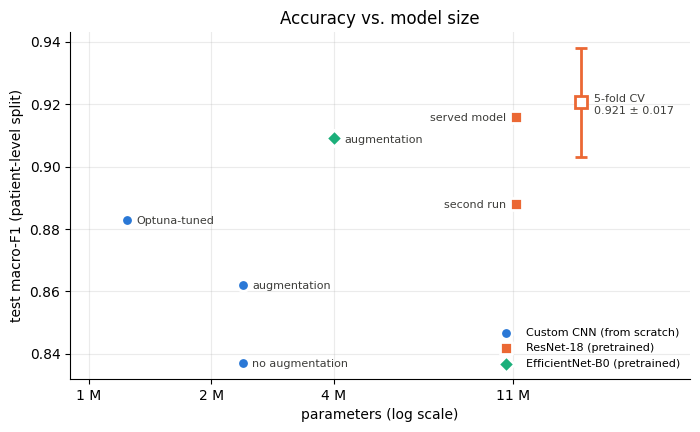

In [ ]:
# One point per run; the 5 CV folds are summarised as one mean ± std error bar.
# Colour = model family (validated categorical palette), plus marker shape and a direct
# label on every point, so identity never depends on colour alone.
FAMILY = {  # model -> (label, colour, marker)
    "custom_cnn": ("Custom CNN (from scratch)", "#2a78d6", "o"),
    "resnet18": ("ResNet-18 (pretrained)", "#eb6834", "s"),
    "efficientnet_b0": ("EfficientNet-B0 (pretrained)", "#1baf7a", "D"),
}
LABEL = {
    "custom_cnn-noaug": "no augmentation",
    "custom_cnn-aug": "augmentation",
    "custom_cnn-tuned": "Optuna-tuned",
    "resnet18-aug": "served model",
    "resnet18-final": "second run",
    "efficientnet_b0-aug": "augmentation",
}
folds = table[(table["split"] == "split") & table["run"].str.contains("fold")]  # unrounded
single = main[~main["run"].str.contains("fold")]

fig, ax = plt.subplots(figsize=(8, 4.5))
for model, (name, colour, marker) in FAMILY.items():
    rows = single[single["model"] == model]
    ax.scatter(rows["parameters"] / 1e6, rows["test macro-F1"], s=70, color=colour,
               marker=marker, edgecolor="white", linewidth=2, label=name, zorder=3)
    for _, r in rows.iterrows():
        text = LABEL.get(r["run"], r["run"])
        if text:
            left = model == "resnet18"  # keep the right side free for the CV error bar
            ax.annotate(text, (r["parameters"] / 1e6, r["test macro-F1"]), fontsize=8,
                        color="#3d3d3a", xytext=(-7 if left else 7, -3),
                        ha="right" if left else "left", textcoords="offset points")
if len(folds):
    x = folds["parameters"].iloc[0] / 1e6 * 1.45  # to the right of the single runs
    m, s = folds["test macro-F1"].mean(), folds["test macro-F1"].std()
    ax.errorbar(x, m, yerr=s, fmt="s", ms=8, color=FAMILY["resnet18"][1], mfc="white",
                mew=2, elinewidth=2, capsize=4, zorder=3)
    ax.annotate(f"5-fold CV\n{m:.3f} ± {s:.3f}", (x, m), fontsize=8, color="#3d3d3a",
                xytext=(9, -8), textcoords="offset points")

ax.set_xscale("log")
ticks = [1, 2, 4, 11]
ax.set_xticks(ticks, [f"{t} M" for t in ticks])
ax.minorticks_off()
ax.set_xlim(0.9, 30)
ax.set(xlabel="parameters (log scale)", ylabel="test macro-F1 (patient-level split)",
       title="Accuracy vs. model size")
ax.grid(alpha=0.25)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.legend(loc="lower right", frameon=False, fontsize=8)
fig.savefig(OUT / "figures" / "accuracy_vs_size.png", dpi=150, bbox_inches="tight")

## 3. Leakage: patient-level vs image-level split

In [ ]:
leak = table[table["model"].isin(table.loc[table["split"] == "image_split", "model"])]
display(leak[["run", "model", "split", "test accuracy", "test macro-F1"]].round(3))

,run,model,split,test accuracy,test macro-F1
11,resnet18-aug-image_split,resnet18,image_split,0.967,0.963
1,resnet18-aug-fold4,resnet18,split,0.940,0.937
4,resnet18-aug-fold1,resnet18,split,0.933,0.929
5,resnet18-aug-fold0,resnet18,split,0.931,0.925
2,resnet18-aug-fold3,resnet18,split,0.926,0.920
13,resnet18-aug,resnet18,split,0.921,0.916
3,resnet18-aug-fold2,resnet18,split,0.900,0.891
0,resnet18-final,resnet18,split,0.895,0.888


## 4. Cross-validation summary (mean ± std per model)

In [ ]:
# The folds change the train/val split but share the fixed test set, so their test
# scores are directly comparable with the single runs above.
cv = runs[runs["tags.mlflow.runName"].str.contains("fold", na=False)]
if len(cv):
    metrics = {
        "metrics.best_val_macro_f1": "val macro-F1",
        "metrics.test_accuracy": "test accuracy",
        "metrics.test_macro_f1": "test macro-F1",
        **{f"metrics.test_recall_{c}": f"recall {c}" for c in CLASSES},
    }
    summary = (cv.rename(columns=metrics).groupby("tags.model")[list(metrics.values())]
               .agg(["mean", "std"]).round(3))
    display(summary)
else:
    print("No CV runs yet")

val macro-F1        test accuracy        test macro-F1         \
                   mean    std          mean    std          mean    std   
tags.model                                                                 
resnet18          0.932  0.041         0.926  0.016         0.921  0.017   

           recall meningioma        recall glioma        recall pituitary  \
                        mean    std          mean    std             mean   
tags.model                                                                  
resnet18               0.925  0.023          0.95  0.008             0.89   

                   
              std  
tags.model         
resnet18    0.048